In [5]:
Plots.default(
    titlefontsize  = 16,   # título de cada gráfico
    guidefontsize  = 14,   # nombre de los ejes ("Tiempo t [s]")
    tickfontsize   = 12,   # números de los ejes
    legendfontsize = 12,   # leyenda
    linewidth      = 2.5,
    framestyle     = :box,
    fontfamily     = "Computer Modern",   # mismo estilo que LaTeX
    margin         = 5Plots.mm,
)
import Pkg; Pkg.add("LaTeXStrings")

   Resolving package versions...
  No Changes to `C:\Users\anton\.julia\environments\v1.11\Project.toml`
  No Changes to `C:\Users\anton\.julia\environments\v1.11\Manifest.toml`


$x_{0}$ = [200, 0]:  distancia de fallo final |y(T)| = 0.0029999999864838882 m
$x_{0}$ = [0, 30]:  distancia de fallo final |y(T)| = 0.0014999999928789727 m
$x_{0}$ = [200.0,-20.0 ]:  distancia de fallo final |y(T)| = 0.0020000000072265146 m


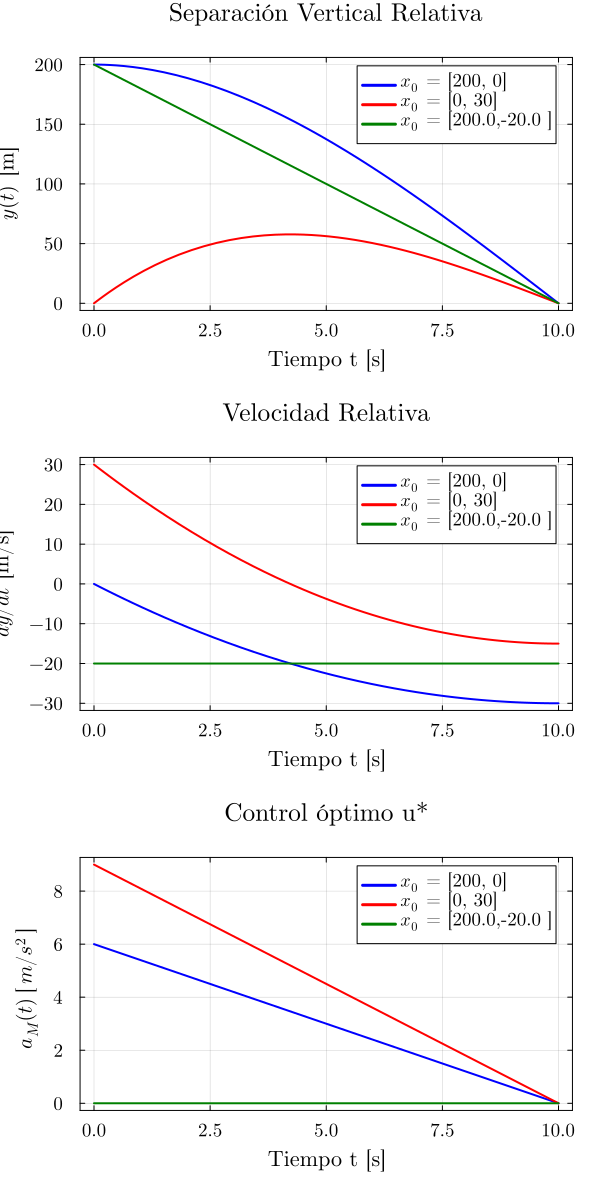

In [10]:
using LinearAlgebra
import DifferentialEquations as DE
import Plots
using LaTeXStrings
const T_final = 10.0      #[s] (T = R0 / Vc = 3000 / 300)
const epsilon = 1e-4      #Evita la división por cero cuando t -> T 
const max_accel = 10 * 9.81  #Límite físico


A = [0.0 1.0; 
     0.0 0.0]

B = [0.0, -1.0]



#u*(t) = (3 / t_go^2) * ZEM(t)
#ZEM(t) = y(t) + y_dot(t) * t_go
function ley_control_optimo(x, t)
    t_go = max(T_final - t, epsilon)
    y, y_dot = x[1], x[2]
    
    zem = y + y_dot * t_go
    # Control sin saturación
    u_opt = (3.0 / (t_go^2)) * zem
    # Acotamiento por límites físicos del actuador
    return clamp(u_opt, -max_accel, max_accel)
end


#Dinámica Continua 

# dx/dt = A*x + B*u(t)
function dinamica_guiado!(dx, x, p, t)
    u = ley_control_optimo(x, t)
    
    # dx1/dt = y_dot
    # dx2/dt = -u(t)
    dx[1] = x[2]
    dx[2] = -u
end


#Solución Numérica para varias condiciones iniciales
tspan = (0.0, T_final - epsilon)

condiciones = [
    ([200.0, 0.0], L"$x_{0}$ = [200, 0]", :blue),
    ([0.0, 30.0],  L"$x_{0}$ = [0, 30]",  :red),
    ([200.0, -20.0], L"$x_{0}$ = [200.0,-20.0 ]", :green),
]

# Gráficos vacíos (se llenan dentro del for)
p1 = Plots.plot(xlabel="Tiempo t [s]", ylabel=L"$y(t)$ [m]",
                title="Separación Vertical Relativa")
p2 = Plots.plot(xlabel="Tiempo t [s]", ylabel=L"$dy/dt$ [m/s]",
                title="Velocidad Relativa")
p3 = Plots.plot(xlabel="Tiempo t [s]", ylabel=L"$a_M(t)\,\, \left[m/s^{2}\right]$ ",
                title="Control óptimo u*")

for (x0, etiqueta, color) in condiciones
    prob = DE.ODEProblem(dinamica_guiado!, x0, tspan)
    sol  = DE.solve(prob, DE.Tsit5(), reltol=1e-8, abstol=1e-8)

    println(etiqueta, ":  distancia de fallo final |y(T)| = ", abs(sol[1, end]), " m")

    u_valores = [ley_control_optimo(sol.u[i], sol.t[i]) for i in eachindex(sol.t)]

    Plots.plot!(p1, sol.t, sol[1, :], label=etiqueta, lw=2, color=color)
    Plots.plot!(p2, sol.t, sol[2, :], label=etiqueta, lw=2, color=color)
    Plots.plot!(p3, sol.t, u_valores, label=etiqueta, lw=2, color=color)
end

Plots.plot(p1, p2, p3, layout=(3, 1), size=(600, 1200), margin=5Plots.mm)

Comparación de leyes de control
Feedback a = 0.5       y(t_final) = 1.02321 m
Feedback a = 1         y(t_final) = 0.00102477 m
Feedback C(t)          y(t_final) = 295.844 m
Feedback K(t)          y(t_final) = 0.035 m
PNG N = 3              y(t_final) = 0.035 m


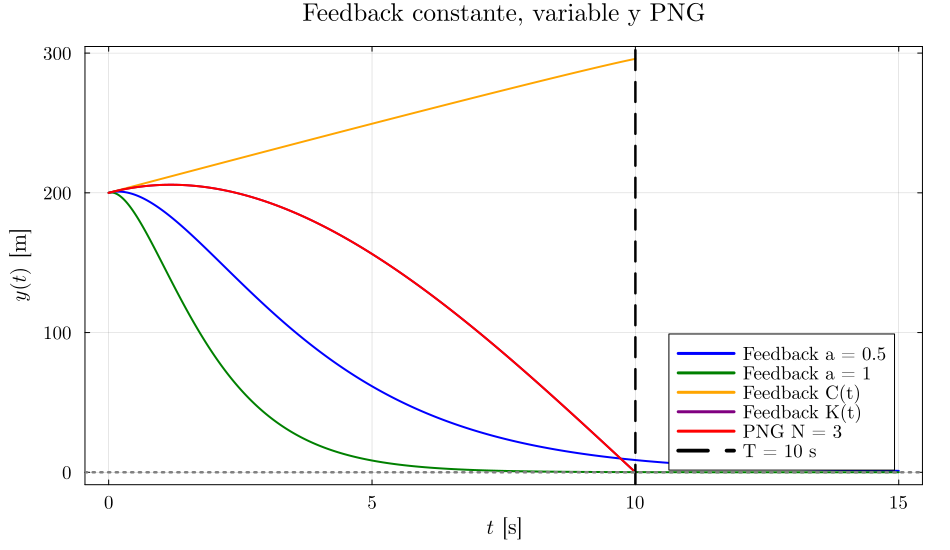


K(t) = [3/tgo², 3/tgo]
Para este modelo, u = K(t)x equivale a PNG N = 3.


In [7]:
using LinearAlgebra
using Plots
using LaTeXStrings

#Parámetros
T = 10.0
Tsim = 15.0
epsilon = 1e-3
x0 = [200.0, 10.0]

A = [0.0 1.0;
     0.0 0.0]

B = [0.0, -1.0]

#RK4
function rk4_comparacion(f, x0, t0, t1, h)
    ts = collect(t0:h:t1)
    X = zeros(length(x0), length(ts))
    X[:, 1] = x0

    for i in 1:length(ts)-1
        t = ts[i]
        x = X[:, i]
        dt = ts[i+1] - ts[i]

        k1 = f(x, t)
        k2 = f(x + dt*k1/2, t + dt/2)
        k3 = f(x + dt*k2/2, t + dt/2)
        k4 = f(x + dt*k3, t + dt)

        X[:, i+1] = x + dt*(k1 + 2k2 + 2k3 + k4)/6
    end

    return ts, X
end

#Feedback u=Kx = k_{1}y+k_{2}\dot{y}
ley_estado(a) = (x,t) ->
    [x[2], -(a^2*x[1] + 2a*x[2])]

#Para definir K(t)=(V_c/t_go^{2}, V_{c}/t_{go})
Vc = 300.0
k = 0.5

ley_salida = (x,t) -> begin
    tg = T - t
    [x[2], -(k/(Vc*tg))*x[1]]
end

#Nueva matriz de ganancia K(t) variable en el tiempo, la que debería lograr que $y(T)=0$.
K_variable(t) = begin
    tg = T - t
    [3.0/tg^2  3.0/tg]
end

ley_K_variable = (x,t) -> begin
    u = (K_variable(t)*x)[1]
    A*x + B*u
end

#PNG con N = 3
ley_PNG = (x,t) -> begin
    tg = T - t
    u = 3*(x[1] + tg*x[2])/tg^2
    A*x + B*u
end

#Gráfico
p = plot(
    xlabel = L"$t$ [s]",
    ylabel = L"$y(t)$ [m]",
    title = "Feedback constante, variable y PNG",
    legend = :bottomright,
    size = (950, 550),
    linewidth = 2
)

casos = [
    ("Feedback a = 0.5", ley_estado(0.5), :blue, Tsim, 1e-3),
    ("Feedback a = 1", ley_estado(1.0), :green, Tsim, 1e-3),
    ("Feedback C(t)", ley_salida, :orange, T-epsilon, 1e-4),
    ("Feedback K(t)", ley_K_variable, :purple, T-epsilon, 1e-4),
    ("PNG N = 3", ley_PNG, :red, T-epsilon, 1e-4)
]

println("Comparación de leyes de control")

for (nombre, f, color, tf, h) in casos
    ts, X = rk4_comparacion(f, x0, 0.0, tf, h)

    plot!(p, ts, X[1,:],
          label = nombre, color = color, lw = 2)

    println(
        rpad(nombre, 22),
        " y(t_final) = ",
        round(X[1,end], sigdigits=6),
        " m"
    )
end

vline!(p, [T], color=:black, linestyle=:dash,
       label="T = 10 s")

hline!(p, [0], color=:gray, linestyle=:dot, label="")

display(p)

#Equivalencia entre K(t) y PNG
println("\nK(t) = [3/tgo², 3/tgo]")
println("Para este modelo, u = K(t)x equivale a PNG N = 3.")